# Projeto 1 · Priorização de ajuda humanitária
**Mineração de Dados — CDIA PUC-SP 2026.2**

Pipeline reproduzível seguindo a ordem das Aulas 1 a 7:

| Etapa | Aula |
|---|---|
| 1. Carga, perfilamento e qualidade (duplicatas, identificador, tipos) | 1–2 |
| 2. Faltantes disfarçados e valores impossíveis → NaN | 2 |
| 3. Imputação: média × mediana × KNN | 2 |
| 4. Outliers: detecção (z-score e IQR) e decisão | 2 |
| 5. Assimetria: transformação log | 3 |
| 6. EDA e correlação de Pearson → escolha dos 4 indicadores | 4 |
| 7. Escalonamento: Min-Max × Z-score × Robust | 3 |
| 8. Métrica de distância | 4 |
| 9. K-Means: cotovelo, silhueta, Calinski-Harabasz, Davies-Bouldin, estabilidade | 5–6 |
| 10. Hierárquico: critérios de ligação, dendrograma e corte | 7 |
| 11. Perfis dos grupos e recomendação | — |

Entrada: `paises_help_international.csv` (mesma pasta). Saídas: pasta `saidas/`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler

warnings.filterwarnings("ignore")
SEED = 42
ARQ = "paises_help_international.csv"
OUT = "saidas"
os.makedirs(OUT, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.9)


def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{nome}.png", dpi=160, bbox_inches="tight")
    plt.close()
    try:  # no Jupyter, mostra a figura salva logo abaixo da célula
        get_ipython  # noqa: F821
        from IPython.display import Image, display
        display(Image(f"{OUT}/{nome}.png", width=800))
    except NameError:
        pass

## 1. Carga, perfilamento e qualidade dos dados (Aulas 1–2)
* `country` é um **campo identificador** (cardinalidade = nº de linhas): fica como
  índice para rastrear cada país, mas **não entra** no agrupamento (Aula 2).
* Todas as 17 variáveis são **numéricas de razão** (Aula 1) — não há categóricas para codificar.
* Checamos **duplicatas** (`.duplicated()`), faltantes (`isnull().sum()`) e faixas (`describe`).

In [2]:
# No Google Colab: se o CSV ainda não estiver na pasta, abre a janela de upload
if not os.path.exists(ARQ):
    try:
        from google.colab import files
        print(f"Envie o arquivo {ARQ}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Coloque {ARQ} na mesma pasta do notebook.")
df_raw = pd.read_csv(ARQ)
print("Formato:", df_raw.shape)
print("country é identificador único?", df_raw["country"].nunique() == len(df_raw))
print("Linhas duplicadas:", df_raw.duplicated().sum(),
      "| países repetidos:", df_raw["country"].duplicated().sum())
df_raw = df_raw.set_index("country")
print("Tipos:", df_raw.dtypes.value_counts().to_dict())
print("\nFaltantes declarados (NaN) por coluna:")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
print("\nPerfilamento (min / mediana / máx) — procurar códigos suspeitos:")
print(df_raw.describe().T[["min", "50%", "max"]])

Formato: (167, 18)
country é identificador único? True
Linhas duplicadas: 0 | países repetidos: 0
Tipos: {dtype('float64'): 15, dtype('int64'): 2}

Faltantes declarados (NaN) por coluna:
child_mort                  1
exports                     1
inflation                   1
life_expec                  1
total_fer                   1
acesso_agua_pct             2
acesso_esgoto_pct           1
acesso_energia_pct          1
alfabetizacao_pct           1
internet_pct                2
medicos_por_1000            1
extrema_pobreza_pct         1
cesta_basica_salario_pct    1
dtype: int64

Perfilamento (min / mediana / máx) — procurar códigos suspeitos:
                               min        50%       max
child_mort                 -8.0000     19.250     208.0
exports                     0.1090     35.200     200.0
health                      1.8100      6.320   99999.0
imports                     0.0659     43.300   99999.0
income                    609.0000  10400.000  125000.0
inflatio

## 2. Faltantes disfarçados e valores impossíveis → NaN (Aula 2)
O perfilamento mostra **faltantes disfarçados** (99999, 999, 100000 — Aula 2, "como detectar
faltantes") e **inconsistências com a regra de negócio** (percentual > 100% ou < 0,
mortalidade negativa, expectativa de vida de 205 anos, 45 filhos por mulher).
Não são outliers válidos: são erros de registro. Viram NaN e são imputados na etapa 3.
`cesta_basica_salario_pct` pode passar de 100% (cesta mais cara que o salário) — é real.

In [3]:
SENTINELAS = [999, 9999, 99999, 100000]
DOMINIO = {
    "child_mort": (0, 1000), "life_expec": (20, 100), "total_fer": (0.5, 10),
    "medicos_por_1000": (0, 10), "health": (0, 100), "inflation": (-50, 1000),
    "acesso_agua_pct": (0, 100), "acesso_esgoto_pct": (0, 100),
    "acesso_energia_pct": (0, 100), "alfabetizacao_pct": (0, 100),
    "internet_pct": (0, 100), "extrema_pobreza_pct": (0, 100),
    "cesta_basica_salario_pct": (0, 1000),
}

df = df_raw.copy().astype(float)
log_limpeza = []
for col in df.columns:
    m = df[col].isin(SENTINELAS)
    for pais in df.index[m]:
        log_limpeza.append((pais, col, df_raw.at[pais, col], "faltante disfarçado (código)"))
    df.loc[m, col] = np.nan
for col, (lo, hi) in DOMINIO.items():
    m = (df[col] < lo) | (df[col] > hi)
    for pais in df.index[m]:
        log_limpeza.append((pais, col, df_raw.at[pais, col], "inconsistente (fora do domínio)"))
    df.loc[m, col] = np.nan

log_limpeza = pd.DataFrame(log_limpeza, columns=["pais", "variavel", "valor_original", "motivo"])
log_limpeza.to_csv(f"{OUT}/log_limpeza.csv", index=False)
print(log_limpeza.to_string(index=False))
print(f"\nNaN declarados: {int(df_raw.isna().sum().sum())} | convertidos em NaN: {len(log_limpeza)} "
      f"| total a imputar: {int(df.isna().sum().sum())} de {df.size} células "
      f"({df.isna().sum().sum() / df.size:.1%})")

      pais                 variavel  valor_original                          motivo
 Guatemala                   health         99999.0    faltante disfarçado (código)
    Poland                   health           999.0    faltante disfarçado (código)
   Morocco                  imports         99999.0    faltante disfarçado (código)
Bangladesh                   income         99999.0    faltante disfarçado (código)
    Turkey                inflation        100000.0    faltante disfarçado (código)
    Uganda                     gdpp         99999.0    faltante disfarçado (código)
     Nepal        acesso_esgoto_pct         99999.0    faltante disfarçado (código)
    Angola       acesso_energia_pct         99999.0    faltante disfarçado (código)
    Zambia        alfabetizacao_pct         99999.0    faltante disfarçado (código)
  Pakistan             internet_pct         99999.0    faltante disfarçado (código)
   Bolivia         medicos_por_1000         99999.0    faltante disfarçado (

## 3. Imputação — média × mediana × KNN (Aula 2)
Remover linhas (listwise) tiraria 33 países, entre eles Haiti, Mali e Tanzânia — inaceitável.
Comparamos as três estratégias vistas em aula. O KNN usa os 5 países mais parecidos em
**todas** as outras variáveis e tira a média deles. Como o KNN mede distâncias, ele roda
no espaço já transformado (log, etapa 5) e padronizado (z-score, Aula 3).
Validação: escondemos 10% dos valores conhecidos (20 repetições) e medimos o erro.

In [4]:
LOG_VARS = ["income", "gdpp", "exports", "imports", "child_mort"]
SIGNED_LOG = ["inflation"]   # tem valores negativos (deflação)


def transformar(d):
    t = d.copy()
    for c in LOG_VARS:
        t[c] = np.log1p(t[c])
    for c in SIGNED_LOG:
        t[c] = np.sign(t[c]) * np.log1p(np.abs(t[c]))
    return t


def destransformar(t):
    d = t.copy()
    for c in [c for c in LOG_VARS if c in d]:
        d[c] = np.expm1(d[c])
    for c in [c for c in SIGNED_LOG if c in d]:
        d[c] = np.sign(d[c]) * np.expm1(np.abs(d[c]))
    return d


def imputar_knn(d, k=5):
    t = transformar(d)
    sc = StandardScaler().fit(t)
    z = pd.DataFrame(sc.transform(t), index=t.index, columns=t.columns)
    z_imp = KNNImputer(n_neighbors=k).fit_transform(z)          # média dos 5 vizinhos
    t_imp = pd.DataFrame(sc.inverse_transform(z_imp), index=t.index, columns=t.columns)
    return destransformar(t_imp)


def imputar_simples(d, estrategia):
    return pd.DataFrame(SimpleImputer(strategy=estrategia).fit_transform(d),
                        index=d.index, columns=d.columns)


metodos = {"Média": lambda d: imputar_simples(d, "mean"),
           "Mediana": lambda d: imputar_simples(d, "median"),
           "KNN (k=5)": imputar_knn}
rng = np.random.default_rng(SEED)
erros = {n: [] for n in metodos}
dp_col = df.std()
for rep in range(20):
    teste = df.copy()
    conhecidos = np.argwhere(teste.notna().values)
    escolha = conhecidos[rng.choice(len(conhecidos), size=int(0.10 * len(conhecidos)), replace=False)]
    verdade = np.array([df.iat[i, j] for i, j in escolha])
    for i, j in escolha:
        teste.iat[i, j] = np.nan
    dp = np.array([dp_col.iloc[j] for _, j in escolha])
    for nome, f in metodos.items():
        imp = f(teste)
        pred = np.array([imp.iat[i, j] for i, j in escolha])
        erros[nome].append(np.mean(np.abs(pred - verdade) / dp))   # erro em desvios-padrão
val_imp = pd.Series({k: np.mean(v) for k, v in erros.items()}).round(3)
print("Erro absoluto médio (em desvios-padrão da coluna), 20 repetições:\n", val_imp)
val_imp.to_csv(f"{OUT}/validacao_imputacao.csv")

df_imp = imputar_knn(df)
assert df_imp.isna().sum().sum() == 0
tab_imp = []
for i, j in zip(*np.where(df.isna())):
    p, c = df.index[i], df.columns[j]
    tab_imp.append((p, c, df_raw.at[p, c], round(df_imp.at[p, c], 2),
                    round(df[c].median(), 2)))
tab_imp = pd.DataFrame(tab_imp, columns=["pais", "variavel", "original", "imputado_KNN", "mediana_da_coluna"])
tab_imp.to_csv(f"{OUT}/valores_imputados.csv", index=False)
print(tab_imp.to_string(index=False))

Erro absoluto médio (em desvios-padrão da coluna), 20 repetições:
 Média        0.798
Mediana      0.774
KNN (k=5)    0.288
dtype: float64
       pais                 variavel  original  imputado_KNN  mediana_da_coluna
Afghanistan             internet_pct       NaN          8.06              42.10
     Angola       acesso_energia_pct   99999.0         33.52              66.20
  Argentina                total_fer      45.0          1.96               2.41
 Bangladesh                   income   99999.0       5275.36           10180.00
    Bolivia         medicos_por_1000   99999.0          1.79               2.40
     Brazil          acesso_agua_pct     150.0         78.82              75.40
      Chile               child_mort      -8.0         11.29              19.30
   Colombia cesta_basica_salario_pct       NaN         64.68              75.10
    Ecuador               life_expec       NaN         75.14              73.10
      Egypt         medicos_por_1000      75.0          1.90 

## 4. Outliers — detecção e decisão (Aula 2)
Detectamos com as duas regras da Aula 2: **z-score** (|z| > 3) e **IQR** (fora de
Q1 − 1,5·IQR ou Q3 + 1,5·IQR). Pergunta da aula: *erro ou valor válido?*
Os erros já foram tratados na etapa 2; os extremos que sobram são **reais**
(Haiti, Luxemburgo, Catar, Nigéria, Venezuela) e são justamente os casos que a ONG precisa
enxergar. **Decisão: manter.** A influência deles é reduzida pelo log (etapa 5).

In [5]:
INDICADORES = ["child_mort", "income", "extrema_pobreza_pct", "inflation"]


def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)


def outliers_z(s):
    return ((s - s.mean()) / s.std()).abs() > 3


X_orig = df_imp[INDICADORES]
X_log = transformar(df_imp)[INDICADORES]
tab_out = pd.DataFrame({
    "z>3 (original)": X_orig.apply(outliers_z).sum(),
    "IQR (original)": X_orig.apply(outliers_iqr).sum(),
    "z>3 (após log)": X_log.apply(outliers_z).sum(),
    "IQR (após log)": X_log.apply(outliers_iqr).sum(),
})
print(tab_out)
tab_out.to_csv(f"{OUT}/outliers.csv")
for c in INDICADORES:
    print(f"{c:22s} z>3 original: {list(X_orig.index[outliers_z(X_orig[c])])}")
print("Restantes após log (z>3):",
      {c: list(X_log.index[outliers_z(X_log[c])]) for c in INDICADORES if outliers_z(X_log[c]).any()})

                     z>3 (original)  IQR (original)  z>3 (após log)  \
child_mort                        2               4               0   
income                            4               8               0   
extrema_pobreza_pct               0               0               0   
inflation                         2               5               2   

                     IQR (após log)  
child_mort                        0  
income                            0  
extrema_pobreza_pct               0  
inflation                         3  
child_mort             z>3 original: ['Haiti', 'Sierra Leone']
income                 z>3 original: ['Brunei', 'Kuwait', 'Luxembourg', 'Qatar']
extrema_pobreza_pct    z>3 original: []
inflation              z>3 original: ['Nigeria', 'Venezuela']
Restantes após log (z>3): {'inflation': ['Ireland', 'Seychelles']}


## 5. Assimetria — transformação log (Aula 3)
O scaler muda a **régua**; o log muda a **forma**. Ordem da Aula 3:
limpar → decidir outliers → **log nas variáveis assimétricas** → escalonar → modelar.
`log1p` nas positivas; log com sinal na inflação (tem deflação).

                     antes  depois
child_mort            1.45    0.07
income                2.23   -0.24
extrema_pobreza_pct   0.29    0.29
inflation             5.34   -0.40


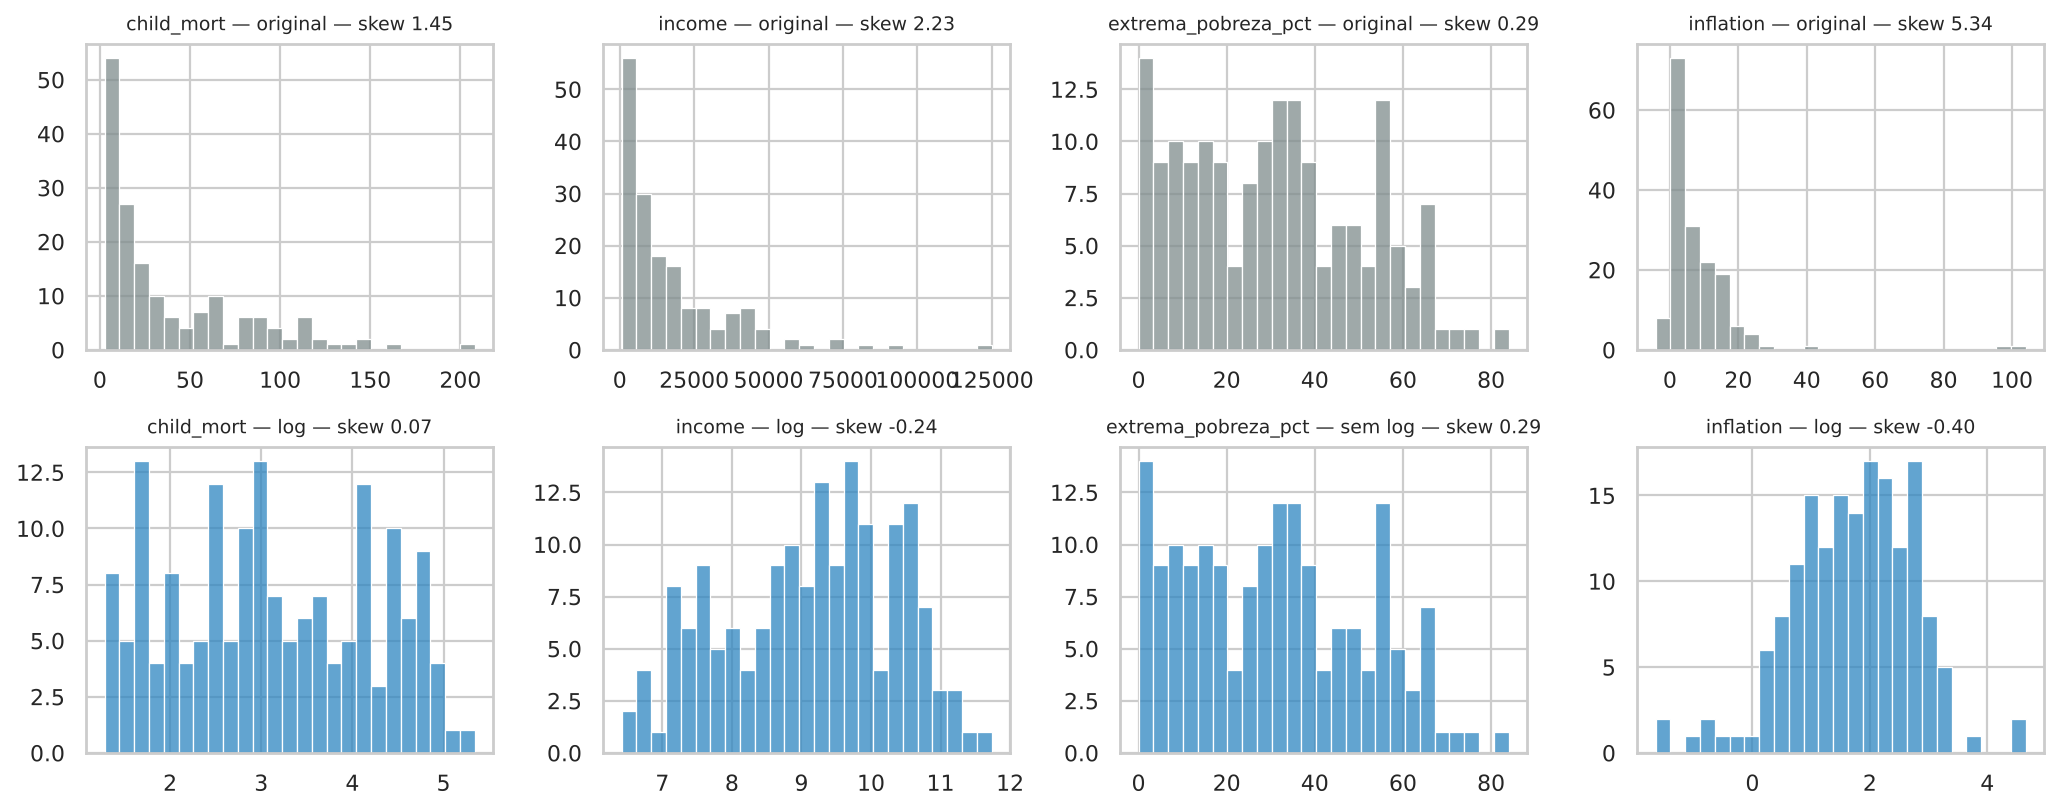

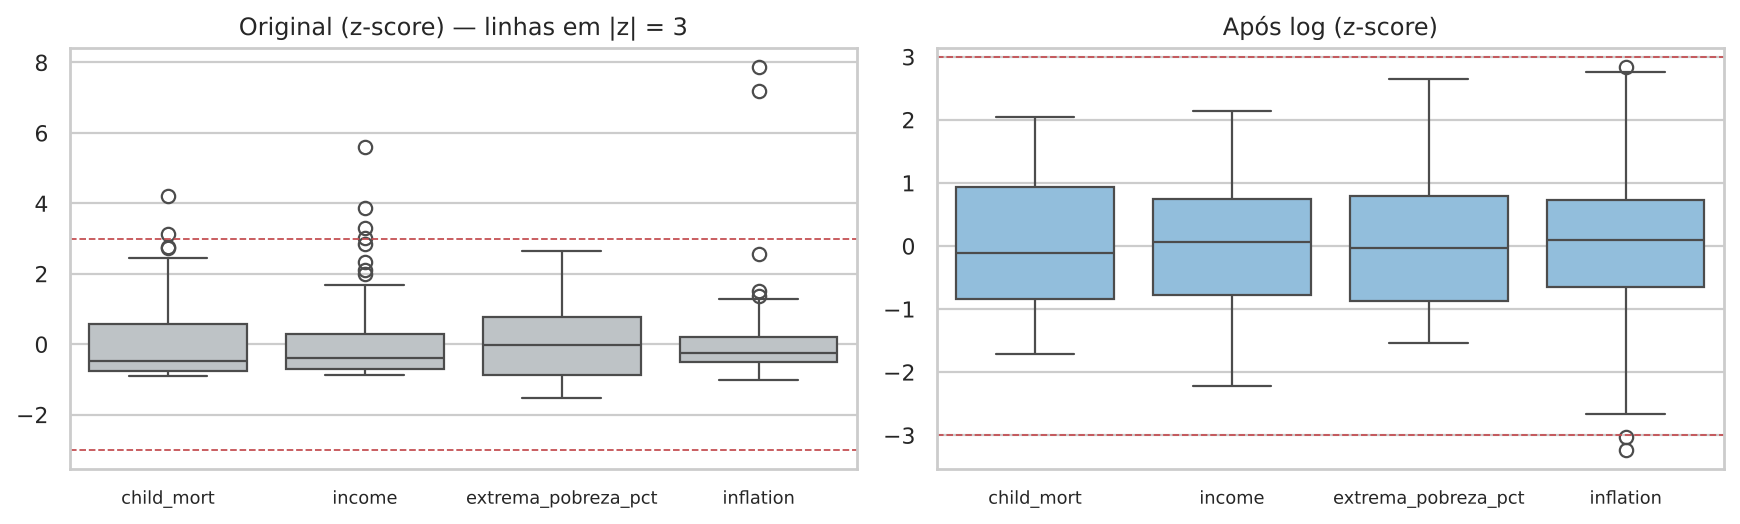

In [6]:
skew = pd.DataFrame({"antes": df_imp.skew(), "depois": transformar(df_imp).skew()}).round(2)
print(skew.loc[INDICADORES])
skew.to_csv(f"{OUT}/assimetria.csv")

fig, axes = plt.subplots(2, 4, figsize=(13, 5.2))
for i, c in enumerate(INDICADORES):
    sns.histplot(X_orig[c], ax=axes[0, i], color="#7F8C8D", bins=25)
    axes[0, i].set_title(f"{c} — original — skew {X_orig[c].skew():.2f}", fontsize=8.5)
    sns.histplot(X_log[c], ax=axes[1, i], color="#2E86C1", bins=25)
    lab = "log" if c != "extrema_pobreza_pct" else "sem log"
    axes[1, i].set_title(f"{c} — {lab} — skew {X_log[c].skew():.2f}", fontsize=8.5)
    for a in axes[:, i]:
        a.set_xlabel(""); a.set_ylabel("")
salvar("fig1_assimetria")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(X_orig), columns=INDICADORES),
            ax=axes[0], color="#BDC3C7")
axes[0].axhline(3, ls="--", c="r", lw=.8); axes[0].axhline(-3, ls="--", c="r", lw=.8)
axes[0].set_title("Original (z-score) — linhas em |z| = 3")
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(X_log), columns=INDICADORES),
            ax=axes[1], color="#85C1E9")
axes[1].axhline(3, ls="--", c="r", lw=.8); axes[1].axhline(-3, ls="--", c="r", lw=.8)
axes[1].set_title("Após log (z-score)")
for a in axes:
    a.tick_params(axis="x", labelsize=8)
salvar("fig2_outliers")

## 6. EDA e correlação de Pearson → escolha dos 4 indicadores (Aula 4)
Pearson mede relação **linear**; por isso calculamos sobre os dados já transformados (log).
O heatmap revela **redundância**: o bloco social (água, esgoto, energia, alfabetização,
internet, médicos, pobreza, cesta, expectativa de vida, fecundidade) anda junto com
`child_mort` (|r| ≈ 0,9). Colocar vários deles contaria a mesma informação várias vezes
na distância. Escolhemos **um indicador por pergunta**.

Spearman (conferência) entre os 4:
                      child_mort  income  extrema_pobreza_pct  inflation
child_mort                 1.00   -0.87                 0.94       0.49
income                    -0.87    1.00                -0.91      -0.32
extrema_pobreza_pct        0.94   -0.91                 1.00       0.43
inflation                  0.49   -0.32                 0.43       1.00


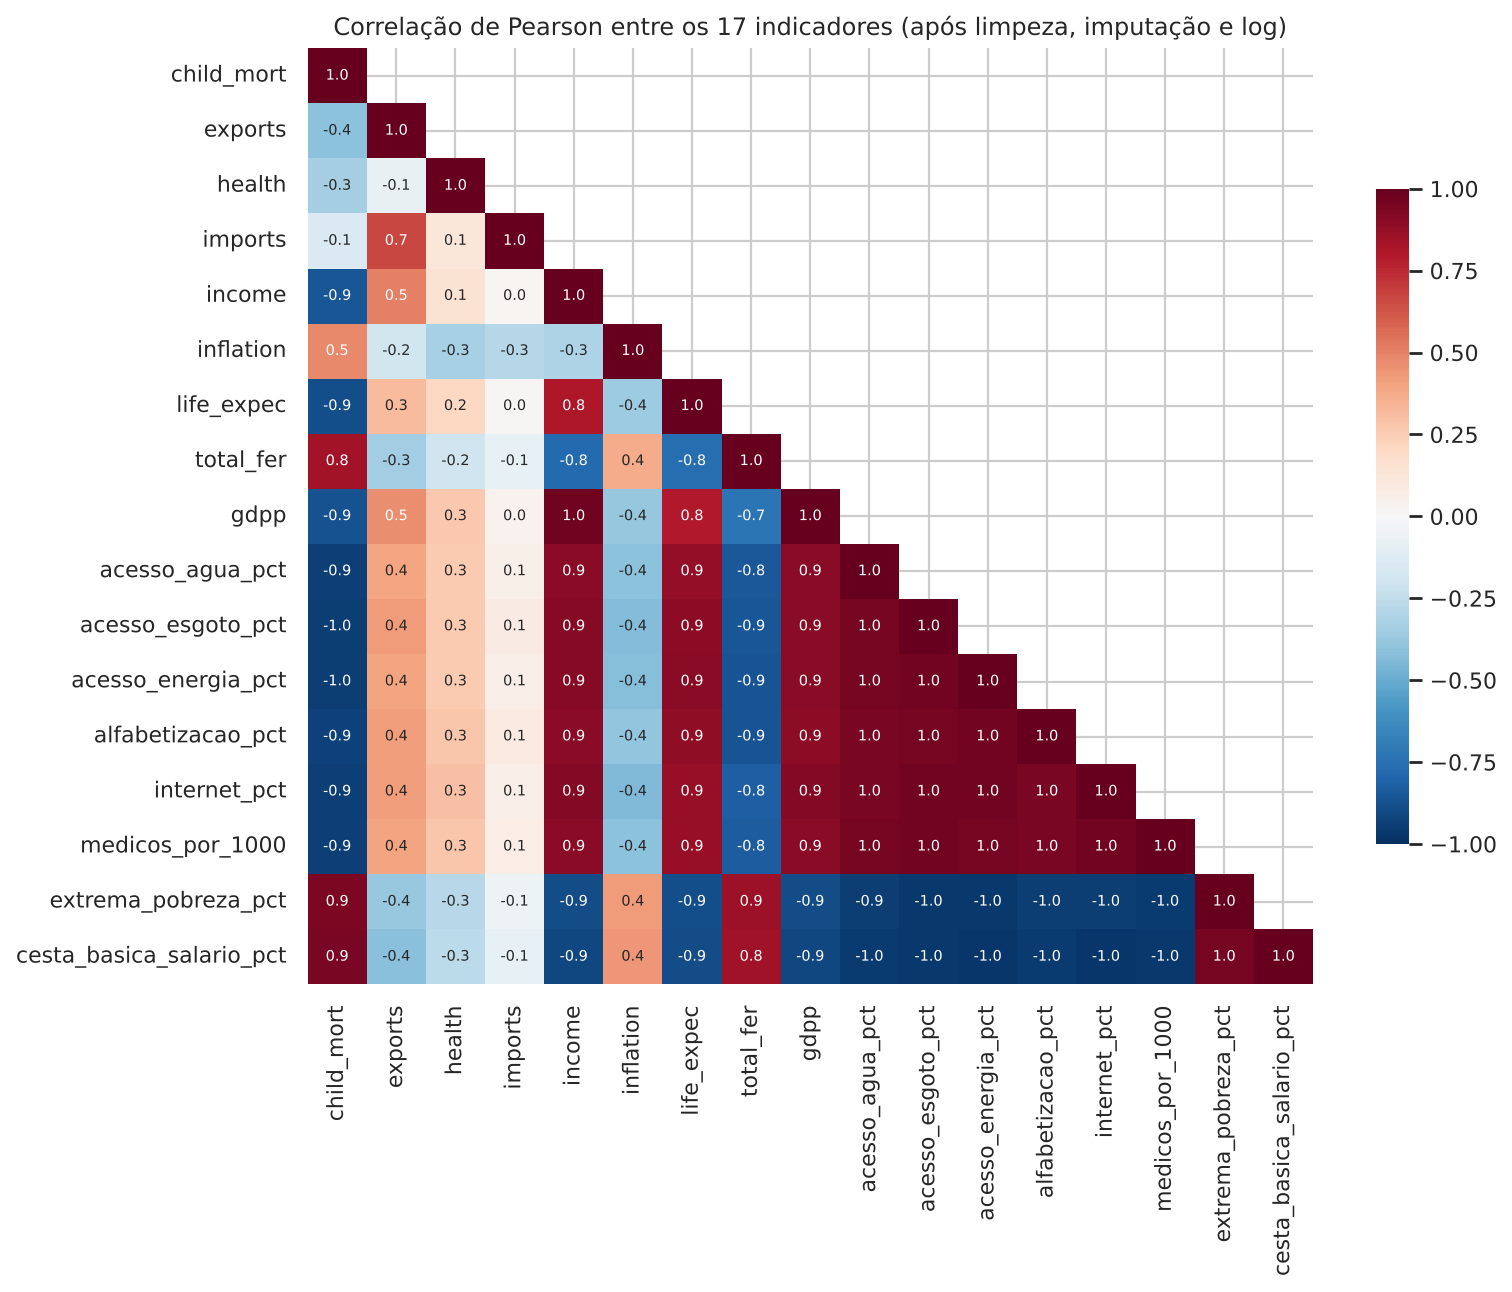

                     child_mort  income  extrema_pobreza_pct  inflation
child_mort                 1.00   -0.86                 0.94       0.48
income                    -0.86    1.00                -0.90      -0.31
extrema_pobreza_pct        0.94   -0.90                 1.00       0.42
inflation                  0.48   -0.31                 0.42       1.00
|r| médio de child_mort com o bloco social: 0.93


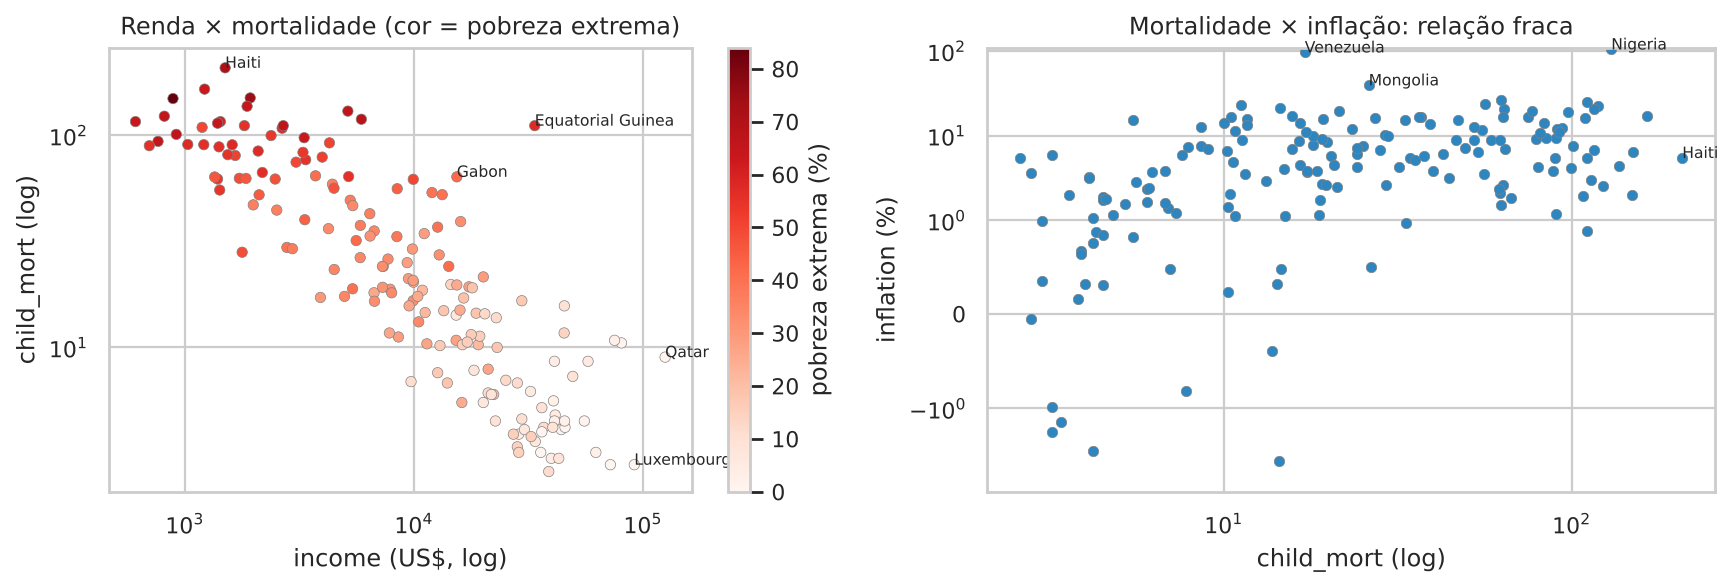

In [7]:
corr = transformar(df_imp).corr(method="pearson")
corr.to_csv(f"{OUT}/correlacao_pearson.csv")
print("Spearman (conferência) entre os 4:\n", df_imp[INDICADORES].corr(method="spearman").round(2))
plt.figure(figsize=(10, 8.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 6.5}, cbar_kws={"shrink": 0.7})
plt.title("Correlação de Pearson entre os 17 indicadores (após limpeza, imputação e log)")
salvar("fig3_correlacao")

bloco = [c for c in df.columns if c.endswith("_pct") or c in ["medicos_por_1000", "life_expec", "total_fer"]]
print(corr.loc[INDICADORES, INDICADORES].round(2))
print("|r| médio de child_mort com o bloco social:",
      corr.loc["child_mort", [c for c in bloco if c != "extrema_pobreza_pct"]].abs().mean().round(2))

# Dispersão (Aula 4: "duas variáveis se relacionam?")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sc_ = axes[0].scatter(df_imp["income"], df_imp["child_mort"], c=df_imp["extrema_pobreza_pct"],
                      cmap="Reds", s=22, edgecolor="grey", lw=.3)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("income (US$, log)"); axes[0].set_ylabel("child_mort (log)")
axes[0].set_title("Renda × mortalidade (cor = pobreza extrema)")
plt.colorbar(sc_, ax=axes[0], label="pobreza extrema (%)")
for p in ["Equatorial Guinea", "Gabon", "Haiti", "Luxembourg", "Qatar"]:
    axes[0].annotate(p, (df_imp.at[p, "income"], df_imp.at[p, "child_mort"]), fontsize=7)
axes[1].scatter(df_imp["child_mort"], df_imp["inflation"], s=22, c="#2E86C1", edgecolor="grey", lw=.3)
axes[1].set_xscale("log"); axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_xlabel("child_mort (log)"); axes[1].set_ylabel("inflation (%)")
axes[1].set_title("Mortalidade × inflação: relação fraca")
for p in ["Nigeria", "Venezuela", "Mongolia", "Haiti"]:
    axes[1].annotate(p, (df_imp.at[p, "child_mort"], df_imp.at[p, "inflation"]), fontsize=7)
salvar("fig4_dispersao")

### 6.1 Teste do 4º indicador
Fixos `child_mort`, `income` e `inflation`, testamos candidatos ao 4º lugar. Critérios:
silhueta (Aula 5), concordância K-Means × Ward (Aula 7) e se 4 países em crise
reconhecida (Haiti, Chade, Rep. Centro-Africana, Serra Leoa) caem no grupo de maior necessidade.

In [8]:
def preparar(cols, d=df_imp):
    return StandardScaler().fit_transform(transformar(d)[cols])


def avaliar(cols, k=4):
    Zc = preparar(cols)
    l = KMeans(k, init="k-means++", n_init=50, random_state=SEED).fit_predict(Zc)
    h = fcluster(linkage(Zc, "ward"), t=k, criterion="maxclust")
    cm = pd.Series(df_imp["child_mort"].values).groupby(l).median()
    crise = ["Haiti", "Chad", "Central African Republic", "Sierra Leone"]
    juntos = sum(l[df_imp.index.get_loc(p)] == cm.idxmax() for p in crise)
    return round(silhouette_score(Zc, l), 3), round(adjusted_rand_score(l, h), 2), f"{juntos}/4"


base = ["child_mort", "income", "inflation"]
cands = ["extrema_pobreza_pct", "acesso_esgoto_pct", "total_fer", "life_expec", "health", "exports"]
tab_cand = pd.DataFrame([(c, *avaliar(base + [c])) for c in cands],
                        columns=["4º indicador", "silhueta", "ARI KMeans×Ward", "crises no grupo A"])
print(tab_cand.to_string(index=False))
tab_cand.to_csv(f"{OUT}/candidatos_indicadores.csv", index=False)

       4º indicador  silhueta  ARI KMeans×Ward crises no grupo A
extrema_pobreza_pct     0.353             0.81               4/4
  acesso_esgoto_pct     0.357             0.44               4/4
          total_fer     0.333             0.67               4/4
         life_expec     0.312             0.47               4/4
             health     0.300             0.57               1/4
            exports     0.277             0.65               4/4


## 7. Escalonamento — Min-Max × Z-score × Robust (Aula 3)
Sem escala, a renda (até 125 mil) decide sozinha a distância. Comparamos os três scalers
depois do log. Como o log já domou os extremos (restam 2 pontos com |z| > 3), os três dão
partições parecidas — "quase qualquer scaler serve" (Aula 3). Ficamos com o **z-score**,
o padrão para distância e para K-Means/hierárquico (Aulas 3, 5 e 7).
Obs.: não há treino/teste em agrupamento, então o `fit` em toda a base não é vazamento.

In [9]:
def contrib(M):
    v = np.var(np.asarray(M), axis=0); return (v / v.sum() * 100).round(1)


scalers = {"Min-Max": MinMaxScaler(), "Z-score": StandardScaler(), "Robust": RobustScaler()}
Zs = {n: s.fit_transform(X_log) for n, s in scalers.items()}
Z = pd.DataFrame(Zs["Z-score"], index=X_log.index, columns=INDICADORES)
lab_ref = KMeans(4, init="k-means++", n_init=50, random_state=SEED).fit_predict(Z)
tab_sc = pd.DataFrame({"sem escala": contrib(X_orig)}, index=INDICADORES)
linhas = []
for n, M in Zs.items():
    tab_sc[n] = contrib(M)
    l = KMeans(4, init="k-means++", n_init=50, random_state=SEED).fit_predict(M)
    linhas.append((n, round(silhouette_score(M, l), 3), round(adjusted_rand_score(lab_ref, l), 3)))
print("Peso (%) de cada variável na variância total (= na distância):\n", tab_sc)
tab_sc.to_csv(f"{OUT}/peso_na_distancia.csv")
tab_sc2 = pd.DataFrame(linhas, columns=["scaler", "silhueta k=4", "ARI vs z-score"])
print(tab_sc2.to_string(index=False))
tab_sc2.to_csv(f"{OUT}/comparacao_scalers.csv", index=False)

Peso (%) de cada variável na variância total (= na distância):
                      sem escala  Min-Max  Z-score  Robust
child_mort                  0.0     34.2     25.0    19.4
income                    100.0     25.3     25.0    26.2
extrema_pobreza_pct         0.0     27.5     25.0    22.2
inflation                   0.0     13.0     25.0    32.2
 scaler  silhueta k=4  ARI vs z-score
Min-Max         0.347           0.747
Z-score         0.353           1.000
 Robust         0.343           0.987


## 8. Métrica de distância (Aula 4)
**Euclidiana** sobre os z-scores: dados numéricos contínuos, poucas dimensões, já escalonados
(Aula 4); é a distância que o K-Means minimiza (inércia = soma das distâncias²) e a única
aceita pelo Ward (Aula 7). Cosseno não serve: ignora a magnitude — um país "um pouco pior em
tudo" e outro "muito pior em tudo" teriam o mesmo perfil. Hamming/Jaccard são para dados
categóricos/conjuntos. Conferência: as distâncias euclidiana e Manhattan entre os pares de países
são quase perfeitamente correlacionadas — a escolha não muda quem é vizinho de quem.

In [10]:
from scipy.spatial.distance import pdist
d_eu = pdist(Z.values, "euclidean"); d_man = pdist(Z.values, "cityblock")
print("Correlação entre as distâncias euclidiana e Manhattan:", round(np.corrcoef(d_eu, d_man)[0, 1], 3))

Correlação entre as distâncias euclidiana e Manhattan: 0.986


## 9. K-Means — escolha de k (Aulas 5 e 6)
Roteiro da Aula 5/6: padronizar → rodar k = 2..10 com `k-means++` e `n_init` alto →
cruzar cotovelo, silhueta, Calinski-Harabasz (↑) e Davies-Bouldin (↓) → verificar
estabilidade → interpretar.

 k  inercia  silhueta  calinski_harabasz  davies_bouldin  estabilidade_ARI  ARI_vs_Ward  queda_inercia
 2  301.436     0.439            200.650           0.836             0.878        0.392            NaN
 3  199.832     0.392            192.111           0.884             0.959        0.735          101.6
 4  163.429     0.353            167.749           0.985             0.921        0.806           36.4
 5  141.496     0.330            150.700           1.022             0.776        0.715           21.9
 6  123.637     0.329            141.774           0.959             0.675        0.617           17.9
 7  107.400     0.315            139.193           0.990             0.779        0.560           16.2
 8   97.527     0.298            132.865           1.022             0.684        0.463            9.9
 9   89.801     0.303            127.164           0.994             0.638        0.527            7.7
10   82.742     0.280            123.389           1.089             0.60

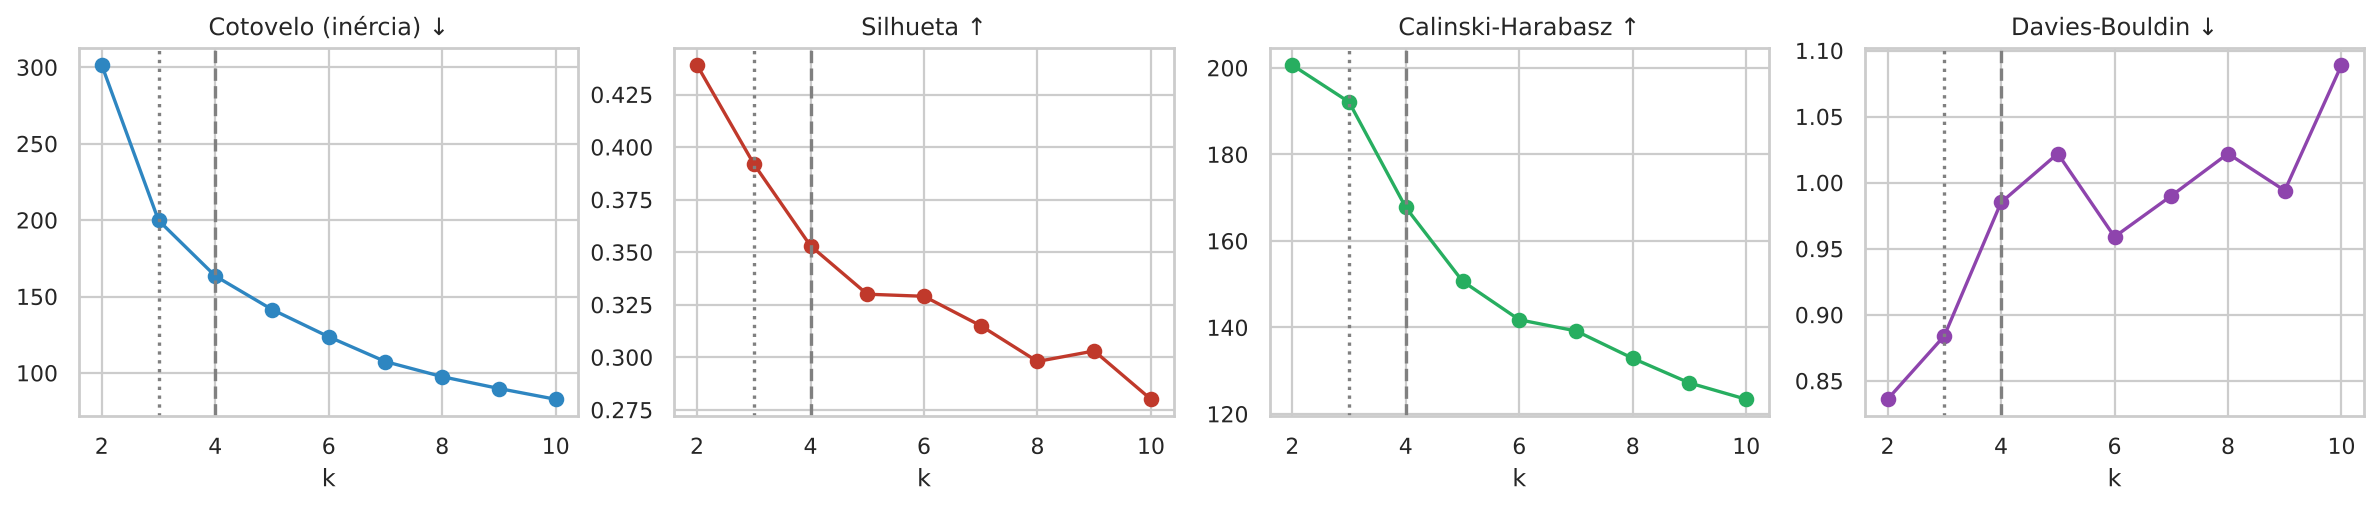

In [11]:
ks = range(2, 11)
res = []
for k in ks:
    km_k = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=SEED).fit(Z)
    l = km_k.labels_
    # estabilidade 1: subamostras de 80% (50 vezes) — ARI com a solução completa
    rng = np.random.default_rng(SEED); boot = []
    for b in range(50):
        idx = rng.choice(len(Z), int(.8 * len(Z)), replace=False)
        lb = KMeans(k, init="k-means++", n_init=10, random_state=b).fit_predict(Z.values[idx])
        boot.append(adjusted_rand_score(l[idx], lb))
    h = fcluster(linkage(Z.values, "ward"), t=k, criterion="maxclust")
    res.append((k, km_k.inertia_, silhouette_score(Z, l), calinski_harabasz_score(Z, l),
                davies_bouldin_score(Z, l), np.mean(boot), adjusted_rand_score(l, h)))
tab_k = pd.DataFrame(res, columns=["k", "inercia", "silhueta", "calinski_harabasz",
                                   "davies_bouldin", "estabilidade_ARI", "ARI_vs_Ward"]).round(3)
tab_k["queda_inercia"] = (-tab_k["inercia"].diff()).round(1)
print(tab_k.to_string(index=False))
tab_k.to_csv(f"{OUT}/escolha_k.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for a, col, cor, tit in zip(axes, ["inercia", "silhueta", "calinski_harabasz", "davies_bouldin"],
                            ["#2E86C1", "#C0392B", "#27AE60", "#8E44AD"],
                            ["Cotovelo (inércia) ↓", "Silhueta ↑", "Calinski-Harabasz ↑", "Davies-Bouldin ↓"]):
    a.plot(tab_k["k"], tab_k[col], "o-", color=cor); a.set_title(tit); a.set_xlabel("k")
    a.axvline(4, ls="--", color="grey"); a.axvline(3, ls=":", color="grey")
salvar("fig5_escolha_k")

**Leitura (Aula 6, "e quando as métricas discordam?")**: silhueta, CH e DB apontam k = 2
(só separa "ricos × pobres", sem utilidade para estratégias); o cotovelo dobra em 3–4; o
maior salto do dendrograma (etapa 10) aponta 3. A regra da aula é "na dúvida, o menor k útil —
**a menos que um 4º grupo real e estável apareça na interpretação**". É o caso: com k = 4 o
grupo intermediário de k = 3 se divide em dois perfis muito diferentes (ver a tabela cruzada),
a solução é estável (ARI ≈ 0,94 em subamostras) e é a que mais concorda com o Ward.

In [12]:
K = 4
km = KMeans(n_clusters=K, init="k-means++", n_init=100, random_state=SEED).fit(Z)
lab_km = pd.Series(km.labels_, index=Z.index)
lab_k3 = pd.Series(KMeans(3, init="k-means++", n_init=100, random_state=SEED).fit_predict(Z), index=Z.index)

# Centróides em unidades originais (Aula 5: "interprete os centróides")
cent = destransformar(pd.DataFrame(StandardScaler().fit(X_log).inverse_transform(km.cluster_centers_),
                                   columns=INDICADORES))
cent["n"] = lab_km.value_counts().sort_index().values
print("Centróides (unidades originais):\n", cent.round(1))

Centróides (unidades originais):
    child_mort   income  extrema_pobreza_pct  inflation   n
0        10.7  26151.2                 15.0       10.5  27
1        28.6   7659.8                 34.6        6.0  52
2        88.3   1861.0                 57.2        7.9  44
3         5.6  28977.9                  9.5        0.6  44


### 9.1 Silhueta por ponto (Aula 5) — países de fronteira

In [13]:
s_pt = pd.Series(silhouette_samples(Z, lab_km), index=Z.index)

## 10. Agrupamento hierárquico (Aula 7)
Sem informação sobre a forma dos grupos, "comece pelo Ward" (Aula 7). Comparamos também
simples, completa e média. Corte: procurar o maior salto entre alturas de fusão e
confirmar com a silhueta.

 k   corte_entre  salto
 2 17.29 e 24.56   7.27
 3  9.43 e 17.29   7.85
 4   6.34 e 9.43   3.10
 5   5.61 e 6.34   0.73
 6   5.44 e 5.61   0.17
 7   5.05 e 5.44   0.39
 8   4.69 e 5.05   0.36
 9   4.30 e 4.69   0.39


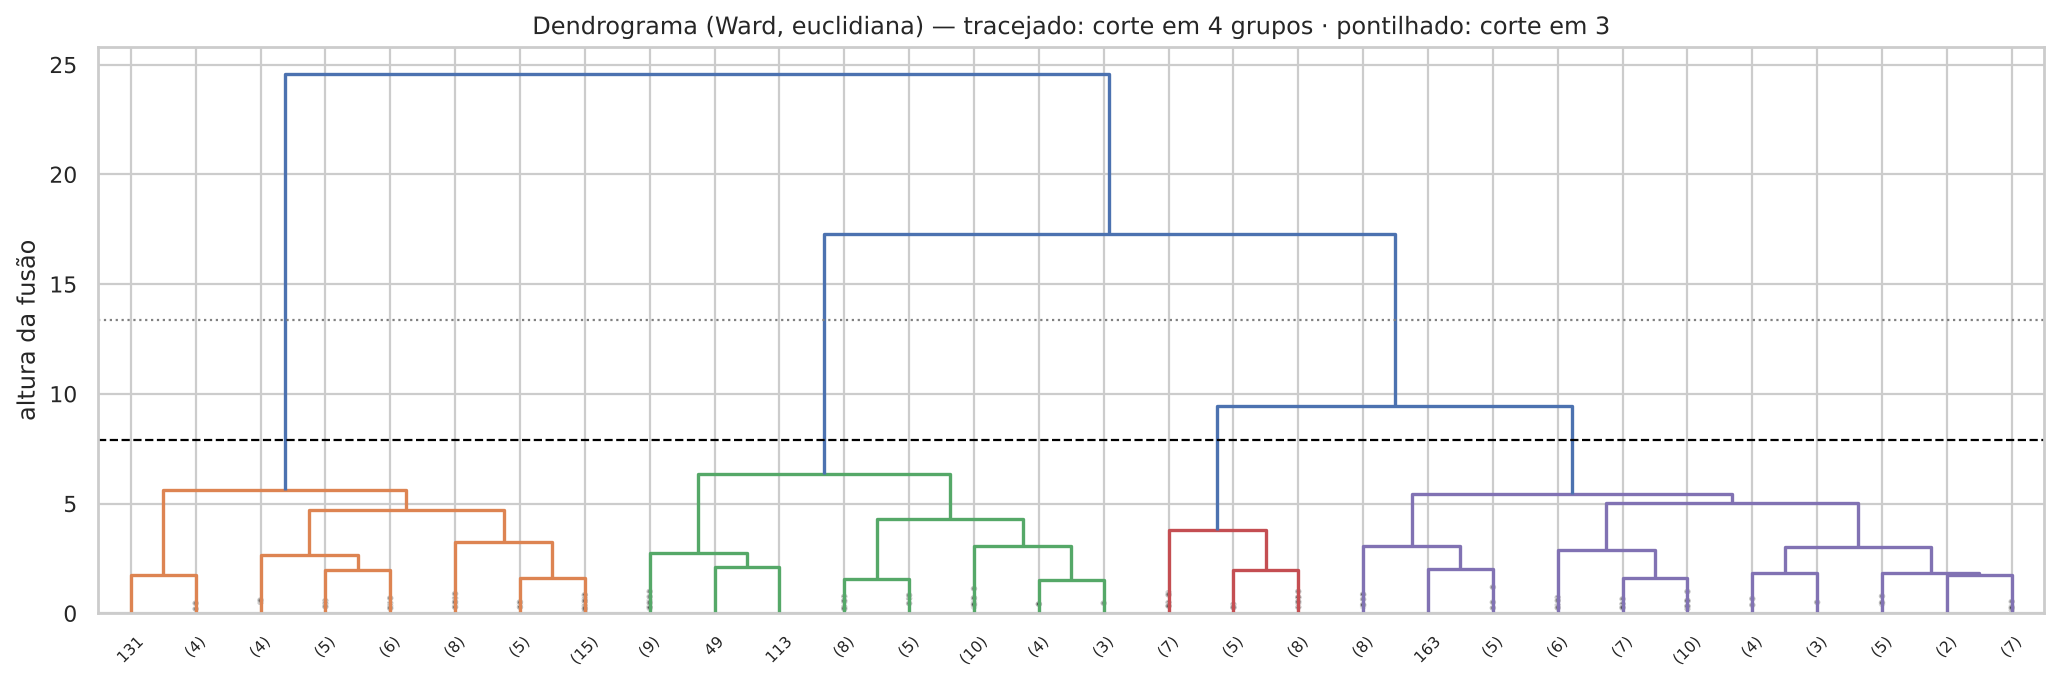

 ligação         tamanhos  silhueta  ARI vs K-Means  NMI vs K-Means
    ward [58, 48, 41, 20]     0.326            0.81            0.79
complete [93, 33, 29, 12]     0.254            0.43            0.60
 average  [108, 56, 2, 1]     0.296            0.38            0.49
  single   [164, 1, 1, 1]     0.112            0.00            0.04


In [14]:
L = linkage(Z.values, method="ward", metric="euclidean")
alturas = L[::-1, 2][:9]          # alturas das últimas fusões, da maior para a menor
# Cortar entre alturas[k-1] e alturas[k-2] deixa k grupos; o "salto" é o tamanho dessa faixa
tab_alt = pd.DataFrame({"k": range(2, 10),
                        "corte_entre": [f"{alturas[k-1]:.2f} e {alturas[k-2]:.2f}" for k in range(2, 10)],
                        "salto": [round(alturas[k-2] - alturas[k-1], 2) for k in range(2, 10)]})
print(tab_alt.to_string(index=False))
tab_alt.to_csv(f"{OUT}/alturas_dendrograma.csv", index=False)

plt.figure(figsize=(13, 4.4))
corte = (L[-K, 2] + L[-K + 1, 2]) / 2
dendrogram(L, truncate_mode="lastp", p=30, color_threshold=corte, leaf_font_size=7, show_contracted=True)
plt.axhline(corte, ls="--", color="black", lw=1)
plt.axhline((L[-3, 2] + L[-2, 2]) / 2, ls=":", color="grey", lw=1)
plt.title(f"Dendrograma (Ward, euclidiana) — tracejado: corte em {K} grupos · pontilhado: corte em 3")
plt.ylabel("altura da fusão")
salvar("fig7_dendrograma")

lab_hc = pd.Series(fcluster(L, t=K, criterion="maxclust") - 1, index=Z.index)
tab_link = []
for met in ["ward", "complete", "average", "single"]:
    l2 = fcluster(linkage(Z.values, method=met), t=K, criterion="maxclust")
    tab_link.append((met, sorted(np.bincount(l2)[1:].tolist(), reverse=True),
                     round(silhouette_score(Z, l2), 3), round(adjusted_rand_score(lab_km, l2), 2),
                     round(normalized_mutual_info_score(lab_km, l2), 2)))
tab_link = pd.DataFrame(tab_link, columns=["ligação", "tamanhos", "silhueta", "ARI vs K-Means", "NMI vs K-Means"])
print(tab_link.to_string(index=False))
tab_link.to_csv(f"{OUT}/comparacao_ligacoes.csv", index=False)

## 11. Perfis dos grupos e recomendação

In [15]:
perfil = df_imp.assign(grupo=lab_km).groupby("grupo")
med = perfil[INDICADORES + ["life_expec", "acesso_esgoto_pct", "medicos_por_1000",
                            "alfabetizacao_pct", "gdpp"]].median()
med["n_paises"] = perfil.size()
ordem = med["child_mort"].sort_values(ascending=False).index
rotulos = ["A · Crise humanitária", "B · Vulnerabilidade estrutural",
           "C · Baixa necessidade, inflação alta", "D · Desenvolvidos e estáveis"]
NOMES = dict(zip(ordem, rotulos))
med.index = [NOMES[g] for g in med.index]
med = med.sort_index()
print(med.round(1).T)
med.round(2).to_csv(f"{OUT}/perfil_grupos.csv")

df_final = df_imp.copy()
df_final["grupo_kmeans"] = lab_km.map(NOMES)
df_final["grupo_ward"] = lab_hc
df_final["grupo_k3"] = lab_k3
df_final["silhueta"] = s_pt.round(3)
for g, paises in df_final.groupby("grupo_kmeans").groups.items():
    print(f"\n{g} ({len(paises)}): {', '.join(sorted(paises))}")

# Como o k = 4 refina o k = 3
ct = pd.crosstab(lab_k3, lab_km.map(NOMES), rownames=["k=3"], colnames=["k=4"])
print(ct); ct.to_csv(f"{OUT}/k3_vs_k4.csv")

# Divergências K-Means × Ward
mapa = {w: df_final.loc[df_final.grupo_ward == w, "grupo_kmeans"].mode()[0] for w in range(K)}
df_final["grupo_ward_nome"] = df_final["grupo_ward"].map(mapa)
diverg = df_final[df_final.grupo_ward_nome != df_final.grupo_kmeans][["grupo_kmeans", "grupo_ward_nome", "silhueta"]]
print(f"\nConcordância K-Means × Ward: {len(df_final) - len(diverg)} de {len(df_final)} países")
print(diverg)
diverg.to_csv(f"{OUT}/divergencias_kmeans_ward.csv")

# Países de fronteira: silhueta negativa
front = df_final[df_final.silhueta < 0][["grupo_kmeans", "silhueta"]].sort_values("silhueta")
print(f"\nSilhueta média por grupo:\n{df_final.groupby('grupo_kmeans').silhueta.mean().round(3)}")
print(f"Países com silhueta negativa ({len(front)}):\n{front}")
front.to_csv(f"{OUT}/paises_fronteira.csv")

                     A · Crise humanitária  B · Vulnerabilidade estrutural  \
child_mort                            90.3                            26.9   
income                              1800.0                          7850.0   
extrema_pobreza_pct                   55.8                            33.9   
inflation                              9.0                             6.0   
life_expec                            60.2                            70.9   
acesso_esgoto_pct                     25.8                            51.6   
medicos_por_1000                       0.7                             2.0   
alfabetizacao_pct                     59.5                            74.8   
gdpp                                 723.0                          3500.0   
n_paises                              44.0                            52.0   

                     C · Baixa necessidade, inflação alta  \
child_mort                                           10.8   
income             

## 12. Visualizações dos grupos

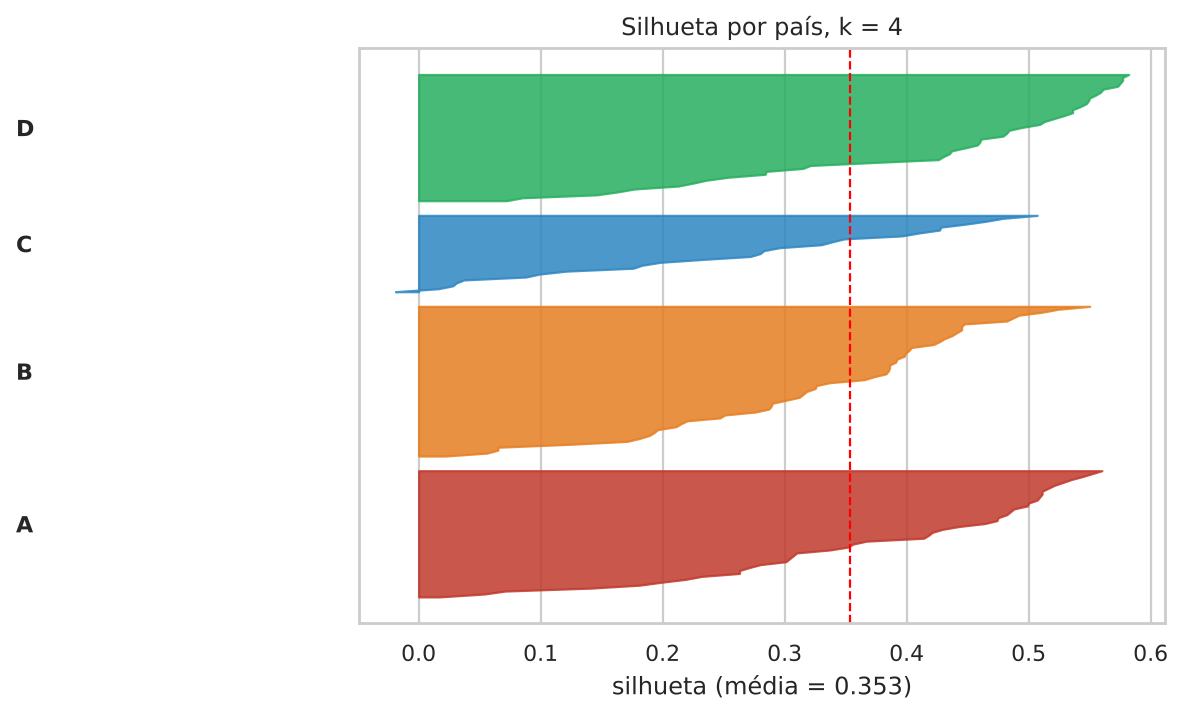

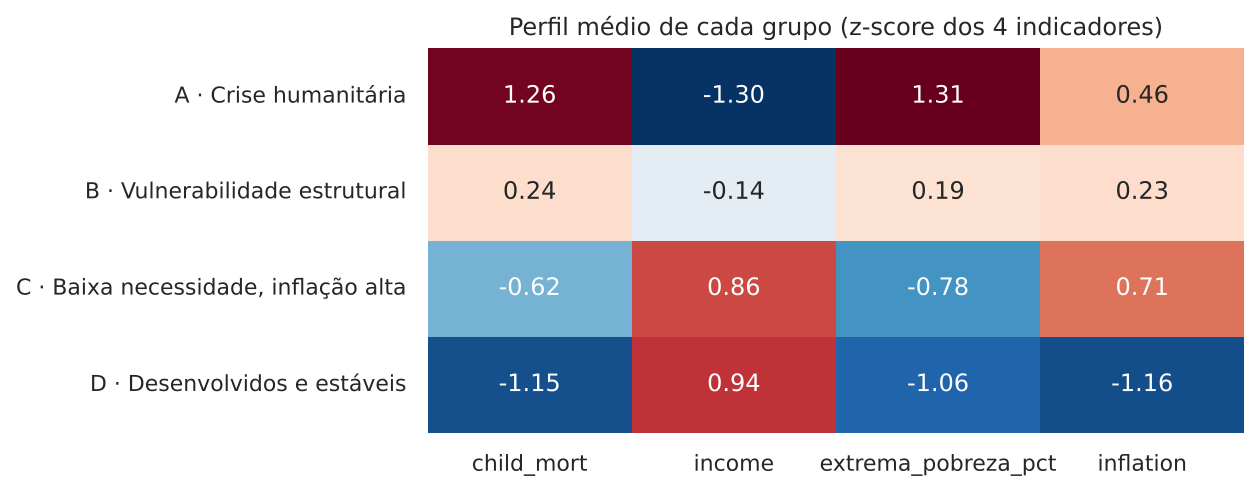

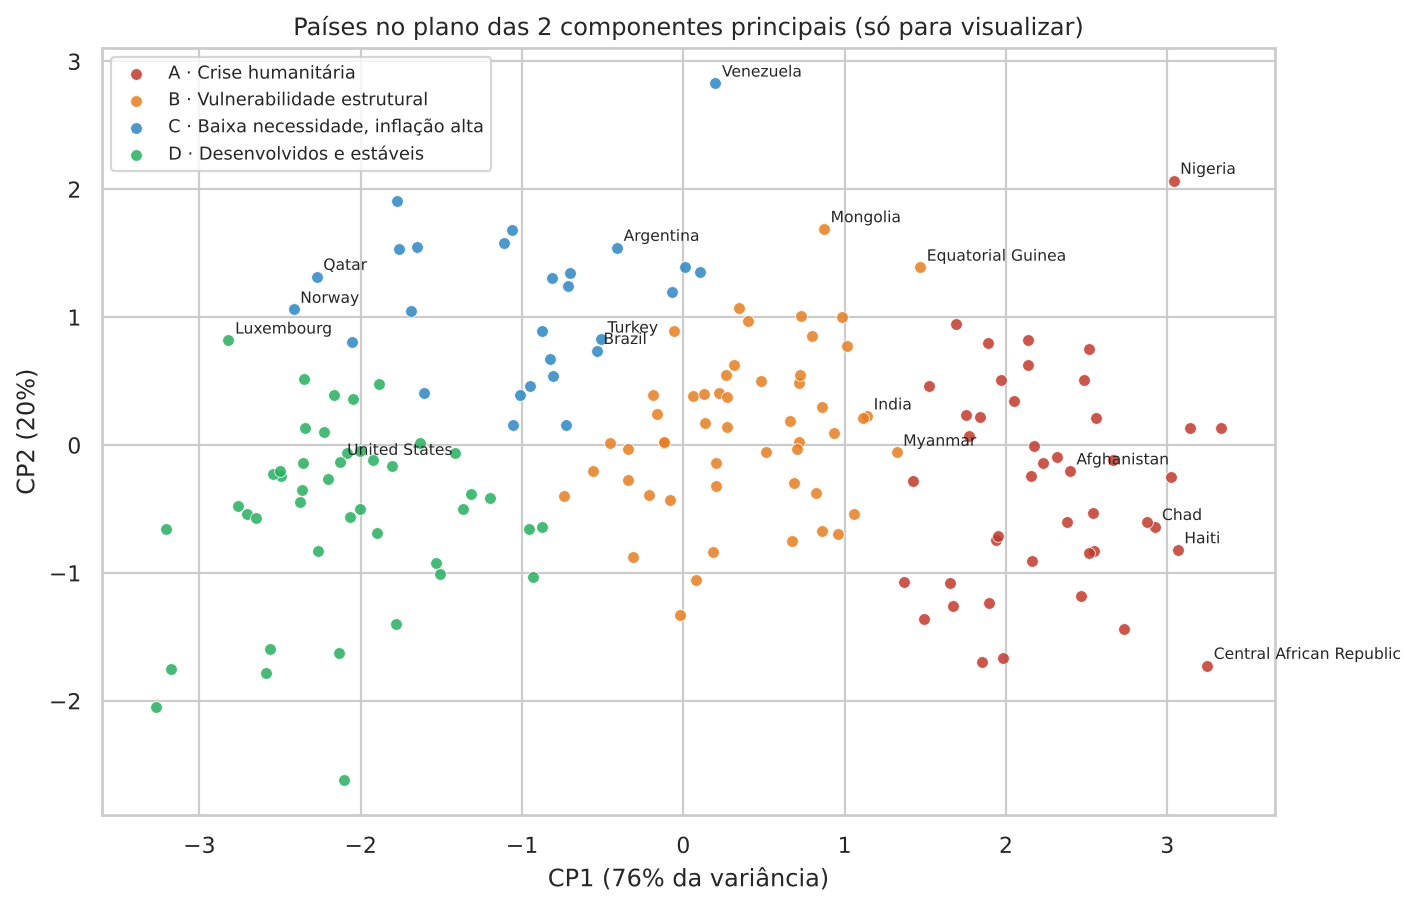

Cargas PCA:
                       CP1   CP2
child_mort           0.56 -0.08
income              -0.53  0.32
extrema_pobreza_pct  0.56 -0.17
inflation            0.33  0.93


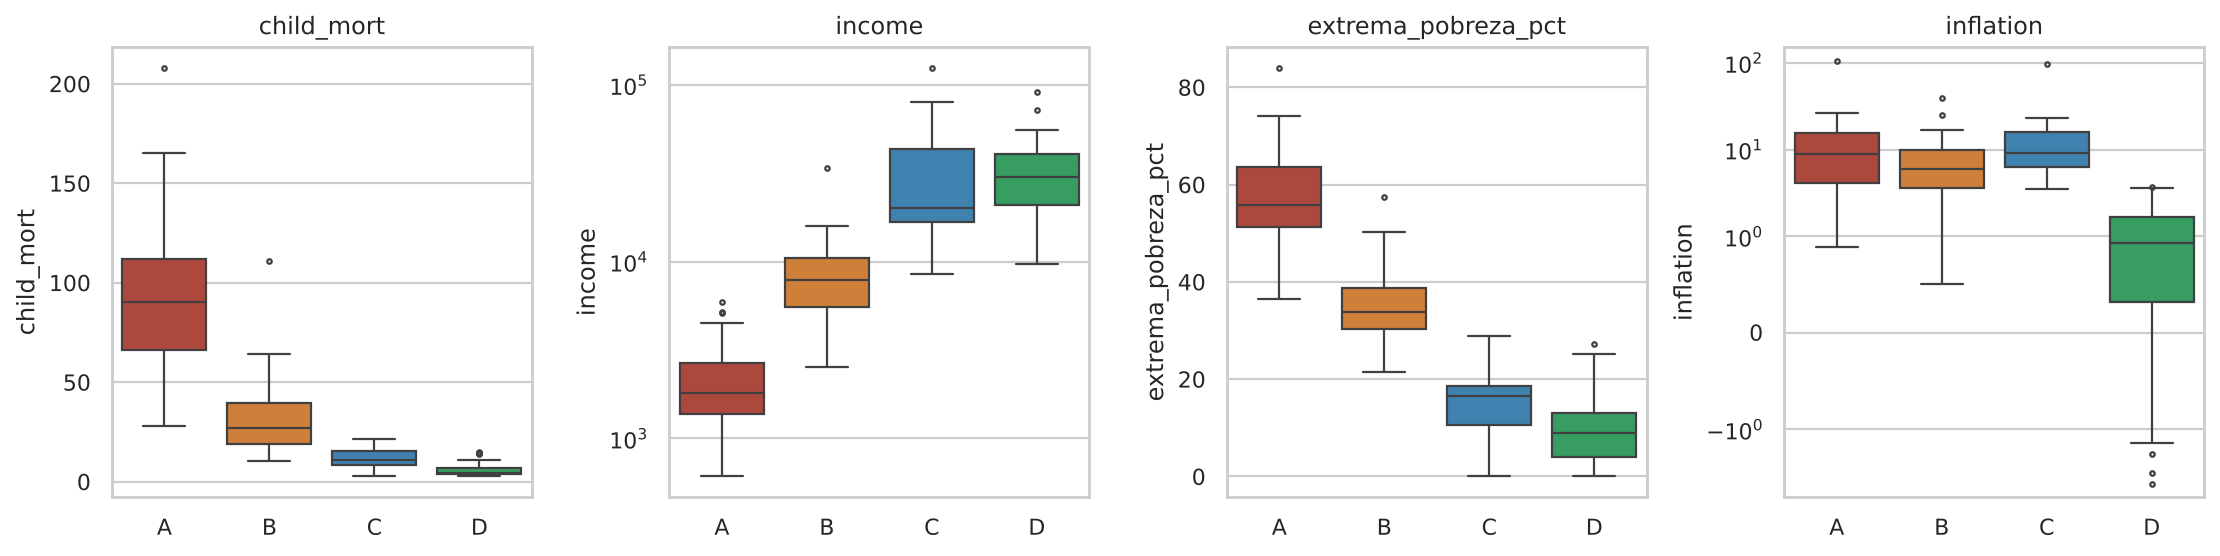

In [16]:
ordem_n = sorted(set(NOMES.values()))
cores = dict(zip(ordem_n, ["#C0392B", "#E67E22", "#2E86C1", "#27AE60"]))

# Gráfico de silhueta ("lâminas", Aula 5)
fig, ax = plt.subplots(figsize=(8, 4.6))
y0 = 0
for n in ordem_n:
    v = np.sort(df_final.loc[df_final.grupo_kmeans == n, "silhueta"].values)
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=cores[n], alpha=.85)
    ax.text(-0.33, y0 + len(v) / 2, n.split(" · ")[0], fontsize=10, weight="bold")
    y0 += len(v) + 4
ax.axvline(s_pt.mean(), color="red", ls="--", lw=1)
ax.set_xlabel(f"silhueta (média = {s_pt.mean():.3f})"); ax.set_yticks([])
ax.set_title("Silhueta por país, k = 4")
salvar("fig6_silhueta")

zprof = Z.assign(g=lab_km.map(NOMES)).groupby("g").mean()
plt.figure(figsize=(8, 3.2))
sns.heatmap(zprof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Perfil médio de cada grupo (z-score dos 4 indicadores)"); plt.ylabel("")
salvar("fig9_perfil_heatmap")

pca = PCA(2, random_state=SEED).fit(Z)
P = pca.transform(Z)
plt.figure(figsize=(9, 5.8))
for n in ordem_n:
    m = (lab_km.map(NOMES) == n).values
    plt.scatter(P[m, 0], P[m, 1], s=28, c=cores[n], label=n, alpha=.85, edgecolor="white", lw=.4)
for p in ["Haiti", "Chad", "Central African Republic", "Nigeria", "Venezuela", "Equatorial Guinea",
          "Brazil", "India", "Luxembourg", "Qatar", "United States", "Afghanistan", "Mongolia",
          "Myanmar", "Turkey", "Argentina", "Norway"]:
    i = Z.index.get_loc(p)
    plt.annotate(p, P[i], fontsize=7, xytext=(3, 3), textcoords="offset points")
ev = pca.explained_variance_ratio_ * 100
plt.xlabel(f"CP1 ({ev[0]:.0f}% da variância)"); plt.ylabel(f"CP2 ({ev[1]:.0f}%)")
plt.legend(fontsize=8); plt.title("Países no plano das 2 componentes principais (só para visualizar)")
salvar("fig8_pca_grupos")
print("Cargas PCA:\n", pd.DataFrame(pca.components_.T, index=INDICADORES, columns=["CP1", "CP2"]).round(2))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for a, c in zip(axes, INDICADORES):
    sns.boxplot(data=df_final, x="grupo_kmeans", y=c, order=ordem_n, palette=cores, ax=a, fliersize=2)
    a.set_xticklabels([n.split(" · ")[0] for n in ordem_n]); a.set_xlabel(""); a.set_title(c)
    if c == "income":
        a.set_yscale("log")
    if c == "inflation":
        a.set_yscale("symlog", linthresh=1); a.set_ylim(-6, 150)
salvar("fig10_boxplots_grupos")

## 13. Ordem de atendimento dentro do grupo A
O agrupamento define **quem** recebe cada estratégia. Para sequenciar o fundo dentro do
grupo A, usamos um índice de necessidade (média dos z-scores de mortalidade, pobreza
extrema e renda invertida) apenas como critério interno.

In [17]:
gA = rotulos[0]
idx = (Z["child_mort"] + Z["extrema_pobreza_pct"] - Z["income"]) / 3
prio = (df_final.assign(indice_necessidade=idx.round(2))
        .loc[df_final["grupo_kmeans"] == gA, INDICADORES + ["life_expec", "indice_necessidade"]]
        .sort_values("indice_necessidade", ascending=False))
print(prio.round(1).head(15).to_string())
prio.round(2).to_csv(f"{OUT}/prioridade_grupo_A.csv")
df_final.round(3).to_csv(f"{OUT}/paises_com_grupos.csv")

# Sensibilidade: trocar pobreza extrema por acesso a esgoto
la = KMeans(K, init="k-means++", n_init=50, random_state=SEED).fit_predict(
    preparar(["child_mort", "income", "acesso_esgoto_pct", "inflation"]))
print(f"Sensibilidade (pobreza → esgoto): ARI = {adjusted_rand_score(lab_km, la):.3f}")
print("\nPipeline concluído. Saídas em ./" + OUT)

# No Google Colab: compacta a pasta saidas/ e baixa (o disco do Colab é apagado ao fechar)
import shutil
shutil.make_archive("saidas", "zip", OUT)
try:
    from google.colab import files
    files.download("saidas.zip")
except ImportError:
    pass

                          child_mort  income  extrema_pobreza_pct  inflation  life_expec  indice_necessidade
country                                                                                                     
Central African Republic       149.0   888.0                 84.0        2.0        47.5                 2.1
Haiti                          208.0  1500.0                 70.8        5.4        32.1                 1.8
Congo, Dem. Rep.               116.0   609.0                 63.5       20.8        57.5                 1.8
Niger                          123.0   814.0                 65.7        2.6        58.8                 1.8
Chad                           150.0  1930.0                 74.2        6.4        56.5                 1.7
Sierra Leone                   165.0  1220.0                 62.8       17.2        55.0                 1.7
Burundi                         93.6   764.0                 65.2       12.3        57.7                 1.7
Mozambique         